# Calibrate your camera

EE 513 lecture 2 demo, and the first measurement of Project 1.

This notebook runs whether or not you have captures yet. Point `CAPTURE_DIR` at a
folder of photographs of the printed calibration target and it will use them. With
no captures it synthesizes a realistic set instead and says so, so that you can
read the whole pipeline before you have shot anything.

The last section is the experiment from the lecture: the same camera calibrated
from a degenerate set of views, where the reprojection error stays small and the
answer is badly wrong.

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.grid": True,
                     "grid.alpha": 0.3})
np.set_printoptions(precision=4, suppress=True)

BOARD = (9, 6)            # inner corners of the printed target
SQUARE_MM = 20.0          # measure yours with a ruler and put the real number here
print("OpenCV", cv2.__version__)

OpenCV 5.0.0


## Which camera took these?

Before anything else. A phone has two or three rear cameras and mixing them inside
one calibration is the quiet way to ruin it. Every DNG records the lens that made it.

In [2]:
import tifffile


def lens_id(path):
    """The fingerprint of the camera that made this raw file."""
    with tifffile.TiffFile(path) as t:
        p = t.pages[0]
        exif = p.tags["ExifTag"].value
        fl = exif["FocalLength"]
        return (exif.get("LensModel", "unknown"),
                round(fl[0] / fl[1], 3),
                exif.get("FocalLengthIn35mmFilm"),
                (p.tags["ImageWidth"].value, p.tags["ImageLength"].value))


def assert_one_camera(paths):
    ids = {lens_id(p) for p in paths}
    if len(ids) != 1:
        raise SystemExit(f"more than one camera in this series:\n  " +
                         "\n  ".join(map(str, ids)))
    return ids.pop()

## The captures

`obj_points` is where the corners are on the board, in millimetres. `img_points` is
where they landed on the sensor, in pixels. Everything downstream needs only those
two lists, so the real and synthetic paths meet here.

In [3]:
CAPTURE_DIR = None        # e.g. Path.home() / "Pictures" / "calibration"

def board_object_points():
    objp = np.zeros((BOARD[0] * BOARD[1], 3), np.float32)
    objp[:, :2] = np.mgrid[0:BOARD[0], 0:BOARD[1]].T.reshape(-1, 2) * SQUARE_MM
    return objp


def from_real_images(folder):
    files = sorted(p for p in Path(folder).iterdir()
                   if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".tif", ".tiff"})
    obj, img, used, shape = [], [], [], None
    crit = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.001)
    for f in files:
        g = cv2.imread(str(f), cv2.IMREAD_GRAYSCALE)
        if g is None:
            continue
        shape = g.shape[::-1]
        ok, corners = cv2.findChessboardCorners(
            g, BOARD, cv2.CALIB_CB_ADAPTIVE_THRESH + cv2.CALIB_CB_NORMALIZE_IMAGE)
        if not ok:
            print(f"  no corners: {f.name}")
            continue
        corners = cv2.cornerSubPix(g, corners, (11, 11), (-1, -1), crit)
        obj.append(board_object_points()); img.append(corners); used.append(f)
    return obj, img, shape, used


def synthetic(n=15, tilt_deg=40.0, noise_px=0.20, seed=513):
    """A believable capture session: varied tilts, sub-pixel corner noise."""
    rng = np.random.default_rng(seed)
    K = np.array([[2795.7, 0, 2015.5], [0, 2795.7, 1511.5], [0, 0, 1]])
    dist = np.array([-0.12, 0.08, 0.0, 0.0, 0.0])
    objp, obj, img = board_object_points(), [], []
    while len(img) < n:
        ax = rng.normal(size=3); ax /= np.linalg.norm(ax)
        rvec = ax * np.radians(rng.uniform(0.35, 1.0) * tilt_deg)
        span = BOARD[0] * SQUARE_MM
        tvec = np.array([rng.uniform(-0.75, 0.15) * span,
                         rng.uniform(-0.75, 0.15) * span * 0.8,
                         rng.uniform(320, 900)])
        p, _ = cv2.projectPoints(objp, rvec, tvec, K, dist)
        p = p.reshape(-1, 2)
        if (p[:, 0].min() > 60 and p[:, 0].max() < 4032 - 60 and
                p[:, 1].min() > 60 and p[:, 1].max() < 3024 - 60):
            obj.append(objp)
            img.append((p + rng.normal(0, noise_px, p.shape)).astype(np.float32)
                       .reshape(-1, 1, 2))
    return obj, img, (4032, 3024), K, dist


if CAPTURE_DIR and Path(CAPTURE_DIR).exists():
    obj_points, img_points, img_shape, used = from_real_images(CAPTURE_DIR)
    TRUTH = None
    print(f"{len(img_points)} of {len(used)} captures gave a full {BOARD} grid")
else:
    obj_points, img_points, img_shape, K_true, dist_true = synthetic()
    TRUTH = (K_true, dist_true)
    print(f"No CAPTURE_DIR set, so these are {len(img_points)} SIMULATED views.")
    print(f"True f_x is {K_true[0,0]:.1f} px, which we get to check against.")

No CAPTURE_DIR set, so these are 15 SIMULATED views.
True f_x is 2795.7 px, which we get to check against.


## Calibrate

`calibrateCameraExtended` returns everything `calibrateCamera` does **plus the
standard deviations of the parameters**. Those uncertainties are the part Project 1
grades, and the last section shows why they matter more than the RMS error.

In [4]:
rms, K, dist, rvecs, tvecs, sd_int, sd_ext, per_view = cv2.calibrateCameraExtended(
    obj_points, img_points, img_shape, None, None)

fx, fy, cx, cy = K[0, 0], K[1, 1], K[0, 2], K[1, 2]
sfx, sfy, scx, scy = sd_int.ravel()[:4]

print(f"RMS reprojection error   {rms:.4f} px\n")
print(f"f_x  {fx:9.2f}  +/- {sfx:.2f} px")
print(f"f_y  {fy:9.2f}  +/- {sfy:.2f} px")
print(f"c_x  {cx:9.2f}  +/- {scx:.2f} px      (image centre {img_shape[0]/2:.1f})")
print(f"c_y  {cy:9.2f}  +/- {scy:.2f} px      (image centre {img_shape[1]/2:.1f})")
print("\ndistortion  k1 k2 p1 p2 k3")
print("  ", dist.ravel())
print("  +/-", sd_int.ravel()[4:9])

if TRUTH is not None:
    print(f"\ntrue f_x {TRUTH[0][0,0]:.1f}, "
          f"error {(fx - TRUTH[0][0,0]) / TRUTH[0][0,0] * 100:+.3f}%")
print(f"\nEXIF predicted 2796 px for the instructor's iPhone 15 Pro. "
      f"Does yours agree with your own prediction?")

RMS reprojection error   0.2798 px

f_x    2794.40  +/- 2.50 px
f_y    2794.33  +/- 2.43 px
c_x    2017.00  +/- 2.47 px      (image centre 2016.0)
c_y    1514.21  +/- 2.12 px      (image centre 1512.0)

distortion  k1 k2 p1 p2 k3
   [-0.1213  0.0968  0.0001  0.0002 -0.0617]
  +/- [0.003  0.0293 0.0002 0.0002 0.0834]

true f_x 2795.7, error -0.047%

EXIF predicted 2796 px for the instructor's iPhone 15 Pro. Does yours agree with your own prediction?


## Undistort

Straightness is the test. Note that the corrected frame **shrinks**: the corrected
image wants pixels at the edges that the sensor never recorded. `alpha` in
`getOptimalNewCameraMatrix` trades that black border against cropping.

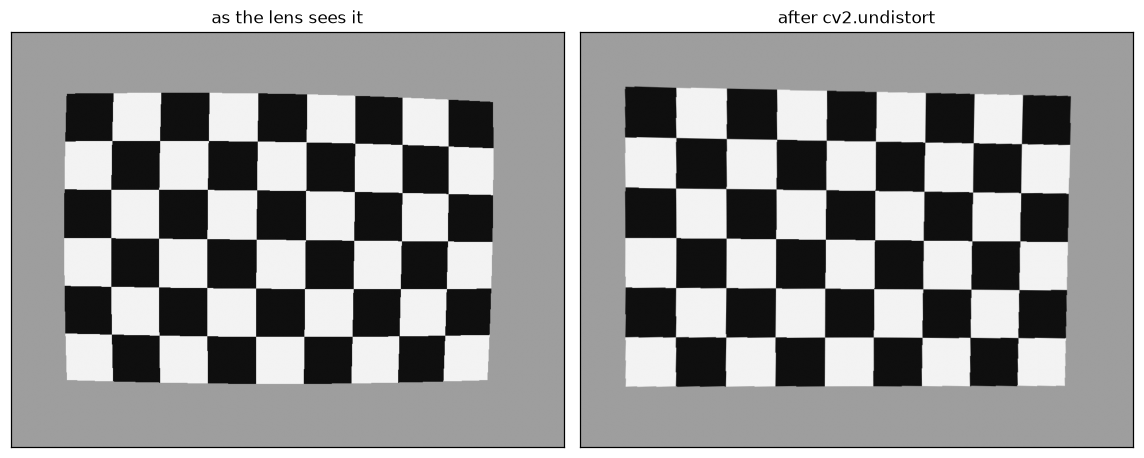

In [5]:
def render_view(K, dist, rvec, tvec, out=(1008, 756), full_w=4032):
    """Analytic render of the printed board as this camera would see it."""
    s = out[0] / full_w
    Ks = K.copy(); Ks[0, :] *= s; Ks[1, :] *= s
    u, v = np.meshgrid(np.arange(out[0]), np.arange(out[1]))
    pix = np.stack([u.ravel(), v.ravel()], 1).astype(np.float64).reshape(-1, 1, 2)
    ideal = cv2.undistortPoints(pix, Ks, dist).reshape(-1, 2)
    R, _ = cv2.Rodrigues(np.asarray(rvec, float))
    t = np.asarray(tvec, float).reshape(3)
    d = np.concatenate([ideal, np.ones((len(ideal), 1))], 1)
    denom = d @ R[:, 2]
    lam = (R[:, 2] @ t) / np.where(np.abs(denom) < 1e-12, np.nan, denom)
    Pb = (d * lam[:, None] - t) @ R
    X, Y = Pb[:, 0], Pb[:, 1]
    inside = ((X >= 0) & (X <= BOARD[0] * SQUARE_MM) &
              (Y >= 0) & (Y <= BOARD[1] * SQUARE_MM) & (lam > 0))
    dark = (np.floor(X / SQUARE_MM) + np.floor(Y / SQUARE_MM)) % 2 == 0
    im = np.full(len(X), 0.62)
    im[inside] = np.where(dark[inside], 0.06, 0.95)
    return im.reshape(out[1], out[0]), Ks


view, Ks = render_view(K, dist, [0.02, -0.03, 0.01], [-92.0, -61.0, 152.0])
fixed = cv2.undistort(view.astype(np.float32), Ks, dist)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.1))
for ax, im, ttl in [(axes[0], view, "as the lens sees it"),
                    (axes[1], fixed, "after cv2.undistort")]:
    ax.imshow(im, cmap="gray", vmin=0, vmax=1)
    ax.set_title(ttl, fontsize=11); ax.set_xticks([]); ax.set_yticks([]); ax.grid(alpha=0)
fig.tight_layout()

## Look at the residuals, not just their average

The RMS error is one number summarising thousands. Plot the residuals where they
happened. Scatter is good. **Structure means the model is wrong**, and the most
common cause is a distortion term you did not fit.

residual mean [-0. -0.] px, sd [0.197  0.1986] px


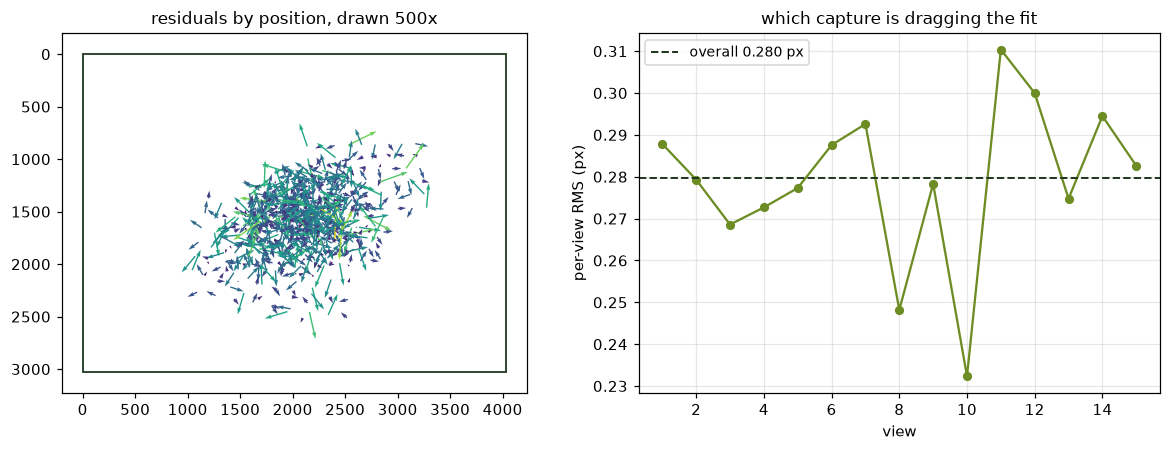

In [6]:
res, pos = [], []
for i in range(len(obj_points)):
    proj, _ = cv2.projectPoints(obj_points[i], rvecs[i], tvecs[i], K, dist)
    res.append(proj.reshape(-1, 2) - img_points[i].reshape(-1, 2))
    pos.append(img_points[i].reshape(-1, 2))
res, pos = np.vstack(res), np.vstack(pos)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2))
a1.quiver(pos[:, 0], pos[:, 1], res[:, 0], res[:, 1],
          np.linalg.norm(res, axis=1), cmap="viridis",
          angles="xy", scale_units="xy", scale=0.002, width=0.003)
a1.add_patch(plt.Rectangle((0, 0), *img_shape, fill=False, ec="#213921", lw=1.2))
a1.set_xlim(-200, img_shape[0] + 200); a1.set_ylim(img_shape[1] + 200, -200)
a1.set_aspect("equal"); a1.grid(alpha=0)
a1.set_title("residuals by position, drawn 500x", fontsize=11)

a2.plot(np.arange(1, len(per_view) + 1), per_view.ravel(), "o-",
        color="#6d8d24", lw=1.5, ms=5)
a2.axhline(rms, color="#213921", ls="--", lw=1.3, label=f"overall {rms:.3f} px")
a2.set_xlabel("view"); a2.set_ylabel("per-view RMS (px)")
a2.set_title("which capture is dragging the fit", fontsize=11); a2.legend(fontsize=9)
fig.tight_layout()
print(f"residual mean {res.mean(axis=0)} px, sd {res.std(axis=0)} px")

## The experiment: a good number and a wrong answer

This is the lecture's headline. Two calibrations of the **same simulated camera**
with the **same number of views** and the **same corner noise**. The only difference
is how much the board was tilted.

It is run on simulated data on purpose: it is the only way to know the true answer
and therefore the only way to prove the point.

In [7]:
rows = []
for label, tilt in [("varied, 15 to 40 deg", 40.0), ("nearly parallel, under 4 deg", 4.0)]:
    o, im, shp, Kt, dt = synthetic(n=15, tilt_deg=tilt, seed=7)
    r, Kc, dc, _, _, sd, _, _ = cv2.calibrateCameraExtended(o, im, shp, None, None)
    rows.append((label, r, Kc[0, 0], sd.ravel()[0],
                 (Kc[0, 0] - Kt[0, 0]) / Kt[0, 0] * 100))

print(f"{'view set':<30}{'RMS':>8}{'f_x':>11}{'sd':>9}{'error':>10}")
for label, r, f, s, e in rows:
    print(f"{label:<30}{r:>8.3f}{f:>11.1f}{s:>9.1f}{e:>9.2f}%")

print("\nThe reprojection errors are nearly identical.")
print("The focal lengths are not. The standard deviation is what saw the problem.")

view set                           RMS        f_x       sd     error
varied, 15 to 40 deg             0.269     2798.0      3.8     0.08%
nearly parallel, under 4 deg     0.271     2767.9    149.9    -0.99%

The reprojection errors are nearly identical.
The focal lengths are not. The standard deviation is what saw the problem.


### Why

From the derivation: each view gives **two** equations, and $B = K^{-\top}K^{-1}$
has **five** unknowns. Those two equations depend on the board's orientation. If
every board has the same orientation, every view supplies the same two equations,
and fifteen copies of two equations is still two equations.

The set is not noisy. It is **redundant**, and the optimizer cannot tell you that.

In [8]:
# How often does a degenerate set actually mislead you? Repeat it.
worst = {}
for label, tilt in [("varied", 40.0), ("parallel", 4.0)]:
    errs = []
    for seed in range(20):
        o, im, shp, Kt, _ = synthetic(n=15, tilt_deg=tilt, seed=100 + seed)
        _, Kc, *_ = cv2.calibrateCamera(o, im, shp, None, None)
        errs.append(abs(Kc[0, 0] - Kt[0, 0]) / Kt[0, 0] * 100)
    errs = np.array(errs)
    worst[label] = errs
    print(f"{label:<10} median {np.median(errs):6.2f}%   worst {errs.max():8.1f}%   "
          f"over 5%: {(errs > 5).sum()} of {len(errs)}")

varied     median   0.05%   worst      0.2%   over 5%: 0 of 20
parallel   median   2.53%   worst      7.4%   over 5%: 1 of 20


### Try it

- Set `CAPTURE_DIR` to your own photographs and compare the measured $f_x$ against
  the EXIF prediction from the first notebook. They should agree within a percent.
- Drop to your five most fronto-parallel captures and watch the standard deviation
  on $f_x$ grow while the RMS error barely moves.
- Refit with `flags=cv2.CALIB_ZERO_TANGENT_DIST`. If $p_1$ and $p_2$ were consistent
  with zero, the RMS should hardly change, and you have one fewer parameter fitting
  noise.
- Set `SQUARE_MM` to a deliberately wrong value. Which parameters change, and which
  do not? This tells you exactly what the board's scale does and does not fix.